# Лабораторная работа №5

**Классификация бабочек: transfer learning на MobileNetV2**

ФИО: Шеранов Александр Сергеевич  
Группа: БИВТ-24-СП-4

Результаты получены реальным выполнением ячеек. RANDOM_STATE = 42.

## Задание преподавателя

  
- Обучить различные модели глубокого обучения на имеющихся данных  

---
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
#### Теперь по пунктам, что я от вас жду:

1. **Загрузить данные** к себе и считать (read) их в переменные.  

2. **Описать постановку задачи**, что от вас хотят.  
   Какие классы, бинарная или многоклассовая классификация, пример реального применения.  
   Показать по 2–3 примера изображений на класс.

3. **Сделать предобработку данных**:  
   - Проверить битые файлы/повреждённые изображения, привести к единому размеру (например, `224×224`).  
   - Нормализовать по каналам (стандарт для ImageNet: mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)).  
   - Разделить на **train**/**val** (или **train**/**test**).  
   - Оформить данные в `Dataset`/`ImageFolder` и передать в `DataLoader`.

4. **Провести разведочный анализ данных (EDA)**:  
   - Посчитать количество изображений в каждом классе и оценить дисбаланс.  
   - Построить 1–2 гистограммы/барчарта распределения по классам.  
   - Сделать промежуточные выводы (есть ли редкие классы, артефакты, перекрытие классов и т.п.).

5. **Настроить аугментации** (минимум три): `RandomHorizontalFlip`, `RandomRotation`, `ColorJitter`, `RandomResizedCrop` и др.  
   Коротко описать, почему выбраны именно эти аугментации и как они помогают обобщению.

6. **Выбор и обучение модели**:  
   - Базовый вариант: **transfer learning** на `ResNet18`/`MobileNetV2`/`EfficientNetB0` (предобученные веса).  
   - Заменить выходной слой под число классов.  
   - Задать функцию потерь `CrossEntropyLoss`, оптимизатор (`AdamW`/`SGD`) и расписание обучения (кол-во эпох, `lr`).  
   - В процессе обучения логировать `train loss/acc` и `val loss/acc` по эпохам.  
   - Сохранить лучшую модель по `val acc`/минимальному `val loss`.

7. **Посчитать метрики качества** на **train** и **val/test** множествах:  
   - Для классификации: `Accuracy`, `Precision`, `Recall`, `F1` (macro/micro — обосновать выбор).  
   - Построить **матрицу ошибок (Confusion Matrix)**; ROC-кривые.

8. **Сравнить результаты** (если пробовали несколько моделей/настроек):  
   - Какая модель лучше справилась?  
   - Есть ли переобучение (по кривым обучения)?  
   - Какие классы путаются чаще всего и почему?  
   - Что ещё можно улучшить (аугментации, веса классов, больше данных, регуляризация, тонкая настройка `lr` и т.д.)?

9. **Визуализировать предсказания**:  
   - Показать не менее 10 изображений из валидации/теста с предсказанными и истинными классами.  
   - Пометить корректные (`Y`) и ошибочные (`N`) предсказания, сделать краткие выводы.

---

## P.S.
Просьба — делать каждое задание в отдельных ячейках с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа:
- Заголовок  
- Ячейка с кодом  
- Другой заголовок  
- Другая ячейка с кодом

## P.S.S.
Если у вас **многоклассовая** классификация, убедитесь, что последний слой имеет размерность `num_classes`, а для `CrossEntropyLoss` **не** требуется one-hot.  
При сильном дисбалансе рассмотрите: `class weights` в `CrossEntropyLoss`, oversampling/undersampling.


## 1. Загрузка данных и постановка задачи

Вариант: https://www.kaggle.com/datasets/phucthaiv02/butterfly-image-classification . В архиве 6499 размеченных изображений и 2786 изображений без меток. Цель — определить один из 75 классов бабочек по фотографии; это многоклассовая классификация. Практический пример — вспомогательная идентификация вида по фотографии, с обязательной проверкой специалистом при неоднозначности.

Официальный Kaggle test не содержит истинных классов и не годится для расчёта метрик. Поэтому из размеченной части выделяется validation. Перед этим проверяются изображения и удаляются точные RGB-повторы. Изображения с противоречивыми метками, если такие встретятся, исключаются полностью, а не исправляются догадкой.

ZIP ищется в `data/butterfly.zip` или в каталоге Kaggle через переменную окружения `BUTTERFLY_ZIP`. Если архива нет, следующая ячейка скачивает публичный набор; интернет нужен только для первоначальной загрузки данных и предобученных весов. Сохранённые результаты всех ячеек доступны и без повторного обучения.

In [1]:
from pathlib import Path
import io, json, random
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def show_plot(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight")
    display(DisplayImage(data=buf.getvalue()))
    plt.close(fig)

import os, hashlib, zipfile, urllib.request, time
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_curve, roc_auc_score, auc)
from sklearn.preprocessing import label_binarize

torch.set_num_threads(4)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ZIP_PATH = Path(os.environ.get("BUTTERFLY_ZIP", str(ROOT / "data/butterfly.zip")))
if not ZIP_PATH.exists():
    ZIP_PATH.parent.mkdir(parents=True, exist_ok=True)
    url = "https://www.kaggle.com/api/v1/datasets/download/phucthaiv02/butterfly-image-classification"
    with urllib.request.urlopen(url, timeout=120) as response, ZIP_PATH.open("wb") as out:
        import shutil
        shutil.copyfileobj(response, out)
archive = zipfile.ZipFile(ZIP_PATH)
labels = pd.read_csv(archive.open("Training_set.csv"))
unlabeled = pd.read_csv(archive.open("Testing_set.csv"))
print("Размеченных/неразмеченных изображений:", len(labels), len(unlabeled))
print("Классов:", labels.label.nunique(), "; устройство:", DEVICE)
display(labels.head())

Размеченных/неразмеченных изображений: 6499 2786
Классов: 75 ; устройство: cpu


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART


## 2. Проверка файлов, повторы и разбиение

In [2]:
rows = []
for row in labels.itertuples(index=False):
    record = {"filename": row.filename, "label": row.label}
    try:
        raw = archive.read("train/" + row.filename)
        with Image.open(io.BytesIO(raw)) as image:
            image.load()
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            record.update(width=rgb.width, height=rgb.height,
                          pixel_sha256=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(), error="")
    except (KeyError, OSError, ValueError) as error:
        record["error"] = f"{type(error).__name__}: {error}"
    rows.append(record)
audit = pd.DataFrame(rows)
print("Ошибок чтения:", audit.error.ne("").sum())
print("Пропусков меток:", audit.label.isna().sum())
print("Размеры изображений:")
display(audit.groupby(["width", "height"]).size().rename("count").to_frame())
clean = audit.loc[audit.error.eq("") & audit.label.notna()].copy()
conflicting = clean.groupby("pixel_sha256").label.nunique()
conflict_hashes = conflicting[conflicting > 1].index
print("Групп противоречивой разметки:", len(conflict_hashes))
clean = clean.loc[~clean.pixel_sha256.isin(conflict_hashes)].copy()
before = len(clean)
clean = clean.drop_duplicates("pixel_sha256").reset_index(drop=True)
print("Удалено точных повторов сверх первых:", before-len(clean))
class_names = sorted(clean.label.unique())
class_to_index = {name: i for i, name in enumerate(class_names)}
clean["target"] = clean.label.map(class_to_index)
train_df, val_df = train_test_split(clean, test_size=.2, stratify=clean.label, random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
assert set(train_df.pixel_sha256).isdisjoint(set(val_df.pixel_sha256))
assert train_df.target.nunique() == val_df.target.nunique() == len(class_names)
print("После очистки:", len(clean), "; train/val:", len(train_df), len(val_df))
train_df.to_csv(ARTIFACTS / "lab5_train_split.csv", index=False)
val_df.to_csv(ARTIFACTS / "lab5_val_split.csv", index=False)
audit.to_csv(ARTIFACTS / "lab5_image_audit.csv", index=False)
json.dump(class_to_index, (ARTIFACTS / "lab5_classes.json").open("w"), ensure_ascii=False, indent=2)

Ошибок чтения: 0
Пропусков меток: 0
Размеры изображений:
Групп противоречивой разметки: 0
Удалено точных повторов сверх первых: 4
После очистки: 6495 ; train/val: 5196 1299


,,count
width,height,
224,224,6499


## 3. Примеры: по два изображения каждого класса

Ниже представлены все 75 классов. Выбор примеров фиксирован по порядку имён файлов и не зависит от предсказаний модели. Изображения показываются до нормализации.

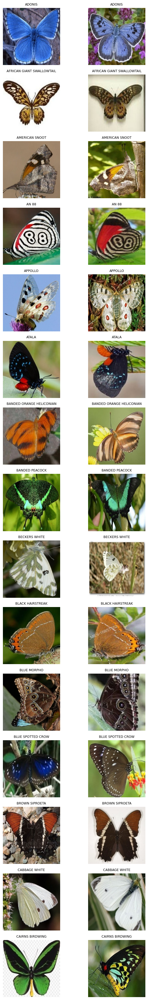

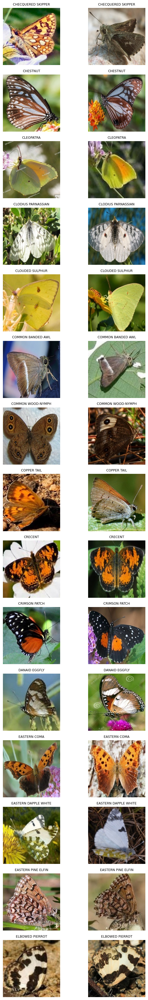

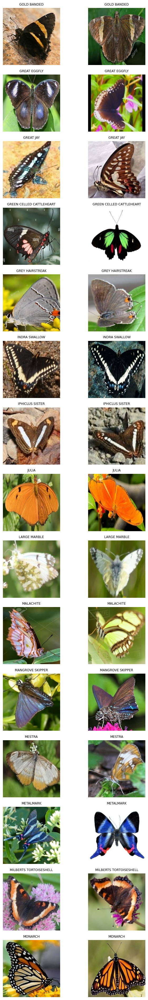

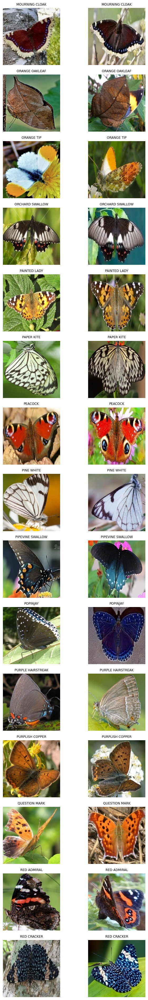

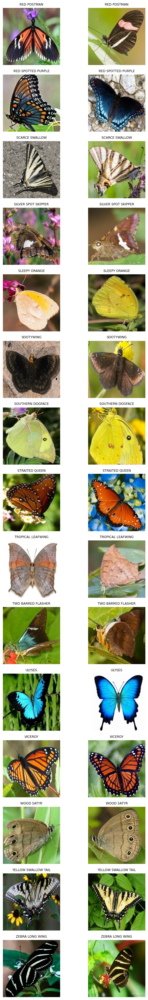

In [3]:
for start in range(0, len(class_names), 15):
    subset = class_names[start:start+15]
    fig, axes = plt.subplots(len(subset), 2, figsize=(7, 2.3*len(subset)), squeeze=False)
    for row_index, name in enumerate(subset):
        examples = clean.loc[clean.label.eq(name)].sort_values("filename").head(2)
        for col, row in enumerate(examples.itertuples(index=False)):
            with Image.open(io.BytesIO(archive.read("train/" + row.filename))) as image:
                axes[row_index, col].imshow(image.convert("RGB"))
            axes[row_index, col].set_title(name, fontsize=8)
            axes[row_index, col].axis("off")
    fig.tight_layout()
    show_plot(fig)

## 4. EDA: распределение классов

Минимум/максимум: 71/131; отношение 1.85.


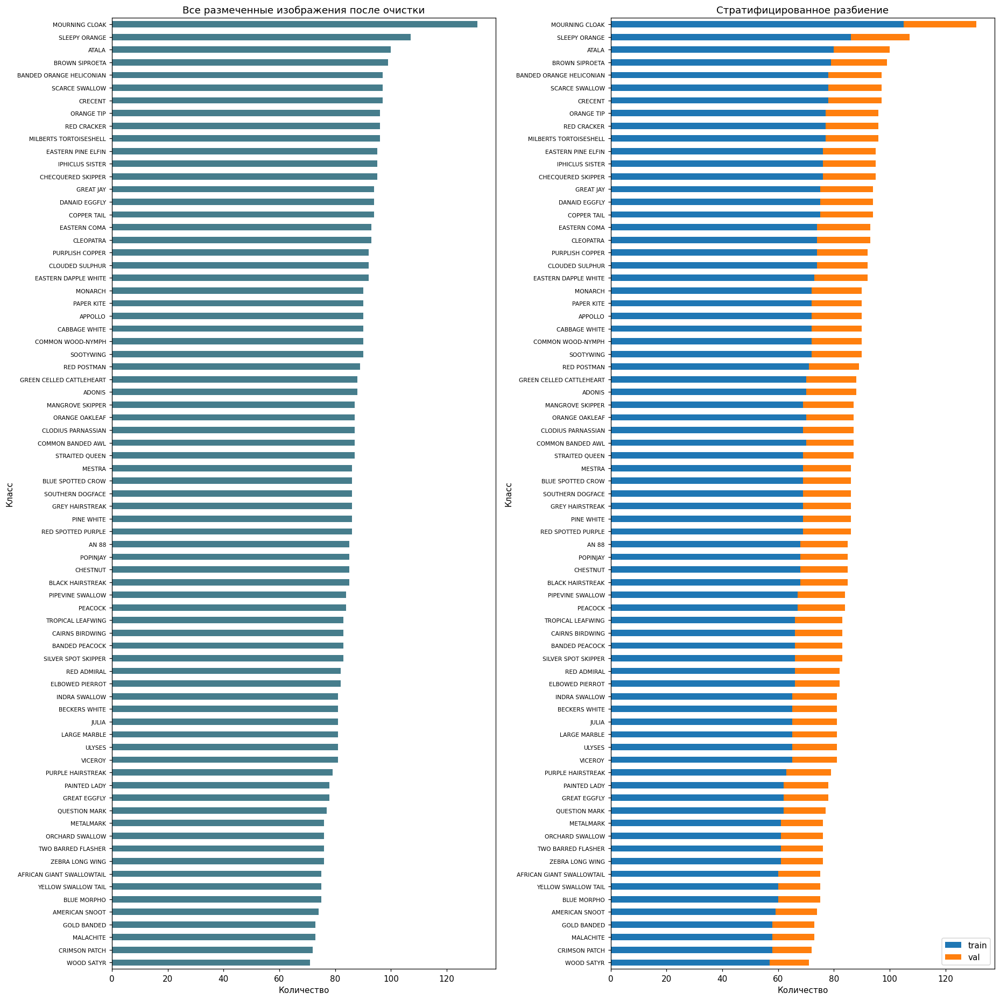

,train,val
label,,
WOOD SATYR,57,14
CRIMSON PATCH,58,14
MALACHITE,58,15
GOLD BANDED,58,15
AMERICAN SNOOT,59,15
...,...,...
BANDED ORANGE HELICONIAN,78,19
BROWN SIPROETA,79,20
ATALA,80,20


In [4]:
counts = clean.label.value_counts().sort_values()
split_counts = pd.concat([train_df.label.value_counts().rename("train"),
                          val_df.label.value_counts().rename("val")], axis=1).reindex(counts.index)
fig, axes = plt.subplots(1, 2, figsize=(17, 17))
counts.plot.barh(ax=axes[0], color="#467d8c")
split_counts.plot.barh(stacked=True, ax=axes[1])
axes[0].set(title="Все размеченные изображения после очистки", xlabel="Количество", ylabel="Класс")
axes[1].set(title="Стратифицированное разбиение", xlabel="Количество", ylabel="Класс")
for ax in axes: ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); show_plot(fig)
print(f"Минимум/максимум: {counts.min()}/{counts.max()}; отношение {counts.max()/counts.min():.2f}.")
display(split_counts)

**Промежуточный вывод.** Числа в таблице и столбцах показывают умеренную неравномерность представленности классов. Стратификация сохраняет все классы в validation. На примерах видны различия фона, положения крыльев, масштаба и освещения, а некоторые классы визуально похожи. Это мотивирует аугментации и transfer learning. Проверка хешем обнаруживает только точные RGB-дубликаты; похожие кадры с изменением масштаба могут остаться и делают оценку потенциально оптимистичной.

## 5. Предобработка, аугментации, Dataset и DataLoader

Изображения приводятся к RGB и размеру **224×224**, затем преобразуются в тензор и нормализуются ImageNet mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225).

Для train применяются четыре случайных преобразования: RandomResizedCrop (разный масштаб/кадрирование), RandomHorizontalFlip (зеркальная ориентация), RandomRotation (наклон), ColorJitter (различия освещения). Небольшие диапазоны уменьшают риск уничтожить рисунок крыльев. Для validation — только детерминированные resize и нормализация.

Для выполнения на CPU используется **замороженный предобученный MobileNetV2 и обучение нового линейного классификатора**. Признаки неизменного backbone извлекаются один раз: чистый train, одна случайно аугментированная версия каждого train-изображения и validation. Потом обучается голова по этим признакам. Аугментации не обновляются каждую эпоху — это ограничение выбранного способа ускорения, а не полное дообучение backbone. Validation не входит в обучающий кеш.

In [5]:
SIZE = 224
normalize = transforms.Normalize(mean=(.485, .456, .406), std=(.229, .224, .225))
eval_transform = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor(), normalize])
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(SIZE, scale=(.8, 1.)),
    transforms.RandomHorizontalFlip(), transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=.15, contrast=.15, saturation=.1),
    transforms.ToTensor(), normalize])

class ButterflyDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True); self.transform = transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(io.BytesIO(archive.read("train/" + row.filename))) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            tensor = self.transform(image)
        return tensor, int(row.target)

image_loaders = {
    "train": DataLoader(ButterflyDataset(train_df, eval_transform), batch_size=48, shuffle=False, num_workers=0),
    "train_aug": DataLoader(ButterflyDataset(train_df, train_transform), batch_size=48, shuffle=False, num_workers=0),
    "val": DataLoader(ButterflyDataset(val_df, eval_transform), batch_size=48, shuffle=False, num_workers=0)}
print("Преобразования train:", train_transform)
print("Batch size изображений: 48; обучение головы: 128.")

Преобразования train: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
Batch size изображений: 48; обучение головы: 128.


## 6. Предобученная модель и извлечение признаков

In [6]:
weights = MobileNet_V2_Weights.DEFAULT
net = mobilenet_v2(weights=weights)
for parameter in net.features.parameters(): parameter.requires_grad = False
net.classifier = nn.Sequential(nn.Dropout(.2), nn.Linear(net.last_channel, len(class_names)))
net = net.to(DEVICE)
print("Модель: MobileNetV2, веса:", weights)
print("Выходных классов:", len(class_names))
print("Обучаемых параметров:", sum(p.numel() for p in net.parameters() if p.requires_grad))
print("Замороженных параметров:", sum(p.numel() for p in net.parameters() if not p.requires_grad))

def extract_features(loader):
    net.eval(); values, targets = [], []
    with torch.no_grad():
        for images, labels_batch in loader:
            features = net.features(images.to(DEVICE)).mean(dim=(2, 3))
            values.append(features.cpu()); targets.append(labels_batch)
    return torch.cat(values), torch.cat(targets)

feature_cache = {}
started = time.perf_counter()
for split, loader in image_loaders.items():
    feature_cache[split] = extract_features(loader)
    print(split, tuple(feature_cache[split][0].shape), f"секунд с начала: {time.perf_counter()-started:.1f}")
assert torch.equal(feature_cache["train"][1], feature_cache["train_aug"][1])

Модель: MobileNetV2, веса: MobileNet_V2_Weights.IMAGENET1K_V2
Выходных классов: 75
Обучаемых параметров: 96075
Замороженных параметров: 2223872
train (5196, 1280) секунд с начала: 70.9
train_aug (5196, 1280) секунд с начала: 152.1
val (1299, 1280) секунд с начала: 171.2


## 7. Обучение головы и сохранение лучшей модели

CrossEntropyLoss принимает логиты и индексы 0–74. Оптимизатор AdamW(lr=0.003, weight_decay=0.0001), 25 эпох, CosineAnnealingLR. Обучающая выборка признаков объединяет чистую и одну аугментированную версию каждого train-объекта. Метрики train по эпохам считаются на чистой версии в режиме eval, поэтому сопоставимы с validation.

Выбор чекпойнта — по максимальной val-Accuracy, при равенстве — по меньшей val-loss. Validation участвует в выборе, поэтому итоговые метрики являются оценкой на validation, а не на независимом финальном тесте. Веса лучшей модели сохраняются целиком вместе с классами и настройками.

Epoch 01: train loss/acc 1.0311/0.8635; val 1.2072/0.8091
Epoch 02: train loss/acc 0.5838/0.9142; val 0.8002/0.8507
Epoch 03: train loss/acc 0.4030/0.9396; val 0.6489/0.8630
Epoch 04: train loss/acc 0.3041/0.9640; val 0.5668/0.8776
Epoch 05: train loss/acc 0.2451/0.9725; val 0.5230/0.8768
Epoch 06: train loss/acc 0.2043/0.9765; val 0.4986/0.8830
Epoch 07: train loss/acc 0.1740/0.9808; val 0.4713/0.8845
Epoch 08: train loss/acc 0.1509/0.9848; val 0.4578/0.8814
Epoch 09: train loss/acc 0.1336/0.9867; val 0.4500/0.8861
Epoch 10: train loss/acc 0.1192/0.9902; val 0.4404/0.8884
Epoch 11: train loss/acc 0.1080/0.9917; val 0.4330/0.8915
Epoch 12: train loss/acc 0.1005/0.9911; val 0.4281/0.8830
Epoch 13: train loss/acc 0.0934/0.9929; val 0.4257/0.8884
Epoch 14: train loss/acc 0.0872/0.9940; val 0.4206/0.8876
Epoch 15: train loss/acc 0.0827/0.9936; val 0.4203/0.8891
Epoch 16: train loss/acc 0.0790/0.9944; val 0.4196/0.8884
Epoch 17: train loss/acc 0.0757/0.9967; val 0.4153/0.8907
Epoch 18: trai

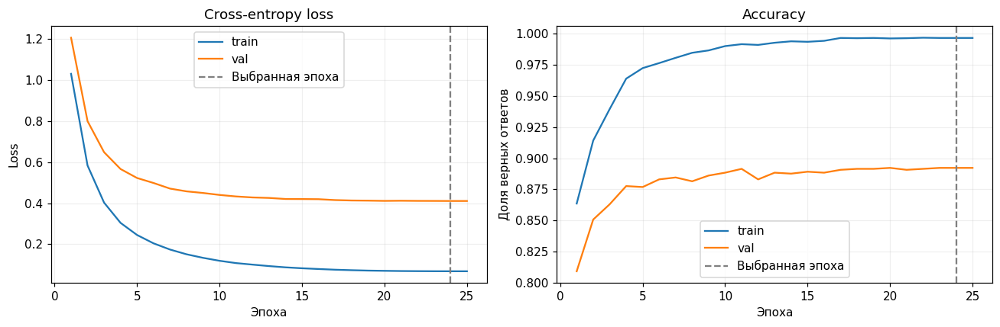

In [7]:
EPOCHS = 25
all_features = torch.cat([feature_cache["train"][0], feature_cache["train_aug"][0]])
all_targets = torch.cat([feature_cache["train"][1], feature_cache["train_aug"][1]])
feature_train = DataLoader(TensorDataset(all_features, all_targets), batch_size=128,
                          shuffle=True, generator=torch.Generator().manual_seed(SEED))
feature_eval = {name: DataLoader(TensorDataset(*feature_cache[name]), batch_size=256, shuffle=False)
                for name in ["train", "val"]}
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(net.classifier.parameters(), lr=.003, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def evaluate_head(loader):
    net.classifier.eval(); total_loss = 0; probability, true = [], []
    with torch.no_grad():
        for features, target in loader:
            target = target.to(DEVICE); logits = net.classifier(features.to(DEVICE))
            total_loss += criterion(logits, target).item() * len(target)
            probability.append(logits.softmax(1).cpu().numpy()); true.extend(target.cpu().tolist())
    probability = np.concatenate(probability)
    true = np.array(true)
    return total_loss / len(true), accuracy_score(true, probability.argmax(1)), true, probability

history = []; best_acc = -1.; best_loss = float("inf"); best_state = None; best_epoch = None
for epoch in range(1, EPOCHS+1):
    net.features.eval(); net.classifier.train()
    for features, target in feature_train:
        features, target = features.to(DEVICE), target.to(DEVICE)
        optimizer.zero_grad(); loss = criterion(net.classifier(features), target)
        loss.backward(); optimizer.step()
    train_loss, train_acc, _, _ = evaluate_head(feature_eval["train"])
    val_loss, val_acc, _, _ = evaluate_head(feature_eval["val"])
    history.append({"epoch": epoch, "lr": optimizer.param_groups[0]["lr"],
                    "train_loss": train_loss, "train_accuracy": train_acc,
                    "val_loss": val_loss, "val_accuracy": val_acc})
    if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
        best_acc, best_loss, best_epoch = val_acc, val_loss, epoch
        best_state = {key: value.detach().cpu().clone() for key, value in net.classifier.state_dict().items()}
    scheduler.step()
    print(f"Epoch {epoch:02d}: train loss/acc {train_loss:.4f}/{train_acc:.4f}; val {val_loss:.4f}/{val_acc:.4f}")
net.classifier.load_state_dict(best_state)
history = pd.DataFrame(history)
history.to_csv(ARTIFACTS / "lab5_history.csv", index=False)
torch.save({"state_dict": {k: v.detach().cpu() for k, v in net.state_dict().items()},
            "architecture": "mobilenet_v2", "class_names": class_names, "image_size": SIZE,
            "normalize_mean": [.485, .456, .406], "normalize_std": [.229, .224, .225],
            "best_epoch": best_epoch, "seed": SEED}, ARTIFACTS / "lab5_best_model.pt")
print("Сохранена лучшая эпоха:", best_epoch)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ["train", "val"]:
    axes[0].plot(history.epoch, history[f"{split}_loss"], label=split)
    axes[1].plot(history.epoch, history[f"{split}_accuracy"], label=split)
for ax in axes:
    ax.axvline(best_epoch, ls="--", color="grey", label="Выбранная эпоха")
    ax.set_xlabel("Эпоха"); ax.legend(); ax.grid(alpha=.2)
axes[0].set(title="Cross-entropy loss", ylabel="Loss")
axes[1].set(title="Accuracy", ylabel="Доля верных ответов")
fig.tight_layout(); show_plot(fig)

## 8. Метрики train/validation и матрица ошибок

,split,average,loss,accuracy,precision,recall,f1,roc_auc_macro_ovr
0,train,macro,0.0681,0.9967,0.9967,0.9967,0.9967,1.0000
1,train,micro,0.0681,0.9967,0.9967,0.9967,0.9967,1.0000
2,val,macro,0.4108,0.8922,0.8984,0.8936,0.8921,0.9975
3,val,micro,0.4108,0.8922,0.8922,0.8922,0.8922,0.9975


,precision,recall,f1-score,support
ADONIS,0.941,0.889,0.914,18.000
AFRICAN GIANT SWALLOWTAIL,1.000,1.000,1.000,15.000
AMERICAN SNOOT,0.909,0.667,0.769,15.000
AN 88,1.000,1.000,1.000,17.000
APPOLLO,1.000,0.833,0.909,18.000
...,...,...,...,...
YELLOW SWALLOW TAIL,1.000,0.933,0.966,15.000
ZEBRA LONG WING,0.938,1.000,0.968,15.000
accuracy,0.892,0.892,0.892,0.892
macro avg,0.898,0.894,0.892,1299.000


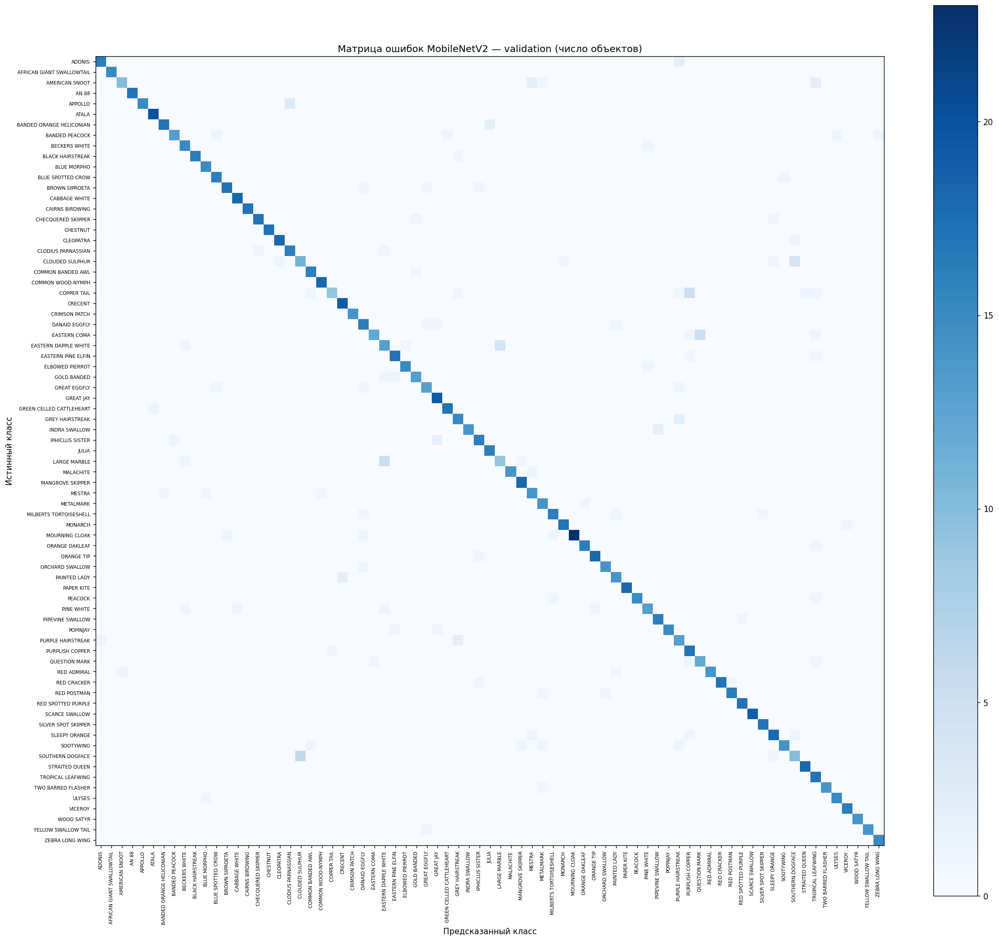

In [8]:
evaluations = {}; metric_rows = []
for split, loader in feature_eval.items():
    loss, accuracy, true, probability = evaluate_head(loader)
    pred = probability.argmax(1); evaluations[split] = (true, probability)
    for average in ["macro", "micro"]:
        precision, recall, f1, _ = precision_recall_fscore_support(true, pred, average=average, zero_division=0)
        metric_rows.append({"split": split, "average": average, "loss": loss,
                            "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1,
                            "roc_auc_macro_ovr": roc_auc_score(true, probability, multi_class="ovr", average="macro")})
metrics = pd.DataFrame(metric_rows)
display(metrics.round(4)); metrics.to_csv(ARTIFACTS / "lab5_metrics.csv", index=False)
true, probability = evaluations["val"]; prediction = probability.argmax(1)
report = pd.DataFrame(classification_report(true, prediction, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0)).T
display(report.round(3)); report.to_csv(ARTIFACTS / "lab5_class_report.csv")
cm = confusion_matrix(true, prediction, labels=np.arange(len(class_names)))
fig, ax = plt.subplots(figsize=(22, 20))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names)), class_names, rotation=90, fontsize=6)
ax.set_yticks(range(len(class_names)), class_names, fontsize=6)
ax.set(xlabel="Предсказанный класс", ylabel="Истинный класс", title="Матрица ошибок MobileNetV2 — validation (число объектов)")
fig.colorbar(im, ax=ax)
show_plot(fig)
np.savetxt(ARTIFACTS / "lab5_confusion_matrix.csv", cm, fmt="%d", delimiter=",")

Macro даёт каждому классу одинаковый вес и помогает увидеть проблемы малых классов. Micro объединяет все решения; для обычной однозначной многоклассовой классификации micro-precision, micro-recall и micro-F1 совпадают с Accuracy. Значение ROC-AUC не заменяет точность выбора одного класса.

## 9. ROC-кривые one-vs-rest на train и validation

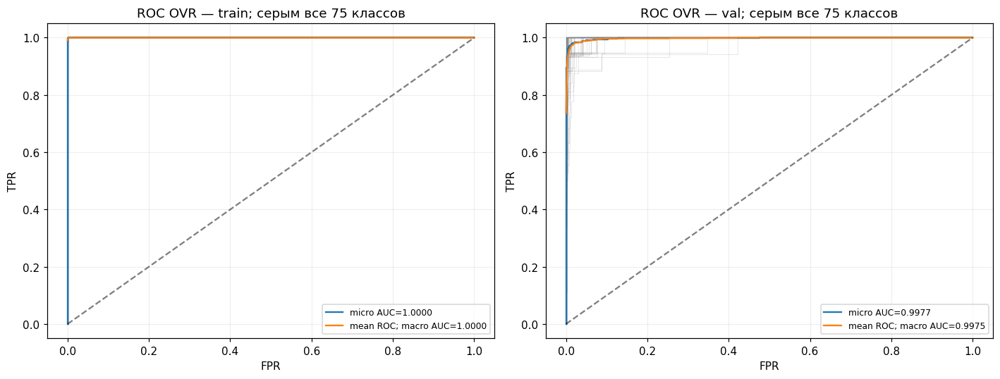

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (split, (true, probability)) in zip(axes, evaluations.items()):
    binary = label_binarize(true, classes=np.arange(len(class_names)))
    grid = np.linspace(0, 1, 501); mean_tpr = np.zeros_like(grid)
    for j in range(len(class_names)):
        fpr, tpr, _ = roc_curve(binary[:, j], probability[:, j])
        mean_tpr += np.interp(grid, fpr, tpr) / len(class_names)
        ax.plot(fpr, tpr, color="grey", alpha=.18, linewidth=.7)
    fpr, tpr, _ = roc_curve(binary.ravel(), probability.ravel())
    ax.plot(fpr, tpr, label=f"micro AUC={roc_auc_score(binary, probability, average='micro'):.4f}")
    ax.plot(grid, mean_tpr, label=f"mean ROC; macro AUC={roc_auc_score(true, probability, multi_class='ovr', average='macro'):.4f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=.5)
    ax.set(title=f"ROC OVR — {split}; серым все 75 классов", xlabel="FPR", ylabel="TPR")
    ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.tight_layout(); show_plot(fig)

## 10. Наиболее частые ошибки и выводы по обучению

In [10]:
confusion_pairs = []
for actual in range(len(class_names)):
    for predicted in range(len(class_names)):
        if actual != predicted and cm[actual, predicted]:
            confusion_pairs.append({"true": class_names[actual], "predicted": class_names[predicted],
                                     "count": int(cm[actual, predicted])})
confusion_pairs = pd.DataFrame(confusion_pairs).sort_values("count", ascending=False)
display(confusion_pairs.head(15))
confusion_pairs.to_csv(ARTIFACTS / "lab5_top_confusions.csv", index=False)
train_true, train_probability = evaluations["train"]
print("Лучшая эпоха:", best_epoch)
print(f"Train/val accuracy: {accuracy_score(train_true, train_probability.argmax(1)):.4f}/{accuracy_score(true, prediction):.4f}")
print(f"Разрыв train−val: {accuracy_score(train_true, train_probability.argmax(1))-accuracy_score(true, prediction):.4f}")
print("Validation участвовала в выборе эпохи; независимого финального теста с метками нет.")

Лучшая эпоха: 24
Train/val accuracy: 0.9967/0.8922
Разрыв train−val: 0.1045
Validation участвовала в выборе эпохи; независимого финального теста с метками нет.


,true,predicted,count
101,SOUTHERN DOGFACE,CLOUDED SULPHUR,6
29,COPPER TAIL,PURPLISH COPPER,5
55,LARGE MARBLE,EASTERN DAPPLE WHITE,5
36,EASTERN COMA,QUESTION MARK,5
40,EASTERN DAPPLE WHITE,LARGE MARBLE,4
24,CLOUDED SULPHUR,SOUTHERN DOGFACE,4
4,APPOLLO,CLODIUS PARNASSIAN,3
3,AMERICAN SNOOT,TROPICAL LEAFWING,2
1,AMERICAN SNOOT,MESTRA,2
0,ADONIS,PURPLE HAIRSTREAK,2


**Вывод.** Кривые и разрыв train/val позволяют оценить переобучение; рост качества train при остановке улучшения val говорит об ограничении обобщения. Таблица ошибок перечисляет конкретные пары перепутанных классов. Сходство окраски и формы, фон и ракурс могут объяснять ошибки, но это гипотезы, требующие просмотра изображений. Обучен один вариант MobileNetV2, поэтому утверждать его превосходство над другими архитектурами нельзя.

Возможные улучшения: частичное размораживание последних блоков с малым lr, новые аугментации на каждой эпохе вместо одной сохранённой версии, расширение данных, проверка похожих дублей, отдельный независимый тест. Class weights здесь не применялись: относительный дисбаланс умеренный, а macro-метрики позволяют его учитывать при оценке.

## 11. Не менее десяти предсказаний на validation

Y — правильный класс; N — ошибка. Эти 10 примеров иллюстрируют ответы, но не заменяют метрики всей validation.


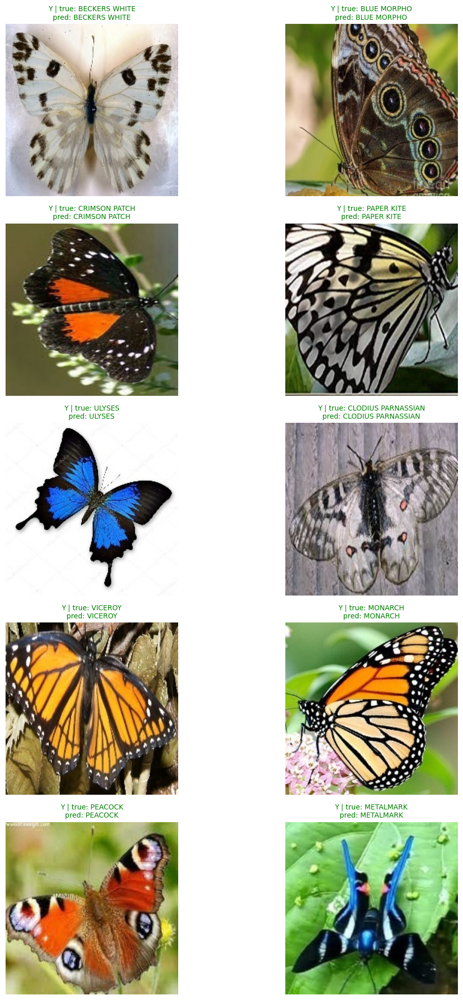

In [11]:
# Десять первых позиций после воспроизводимого разбиения: без отбора только удачных ответов.
positions = np.arange(10)
fig, axes = plt.subplots(5, 2, figsize=(12, 18))
for ax, position in zip(axes.flat, positions):
    row = val_df.iloc[position]
    predicted_name = class_names[int(prediction[position])]
    actual_name = class_names[int(true[position])]
    with Image.open(io.BytesIO(archive.read("train/" + row.filename))) as image:
        ax.imshow(image.convert("RGB"))
    correct = predicted_name == actual_name
    ax.set_title(f"{'Y' if correct else 'N'} | true: {actual_name}\npred: {predicted_name}",
                 fontsize=9, color="green" if correct else "red")
    ax.axis("off")
fig.tight_layout(); show_plot(fig)
print("Y — правильный класс; N — ошибка. Эти 10 примеров иллюстрируют ответы, но не заменяют метрики всей validation.")
archive.close()

## 12. Дополнительный просмотр ошибок и проверка сохранённых весов

Загруженный из сохранённого чекпойнта полный MobileNetV2 воспроизвёл отчётную Accuracy на всей validation.


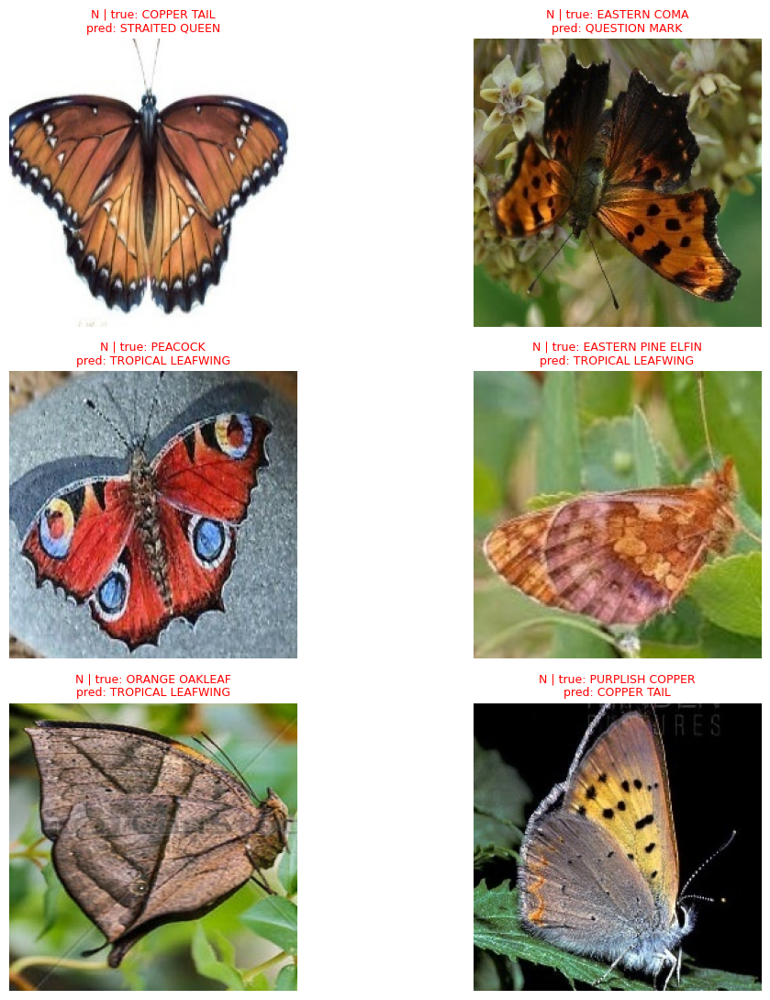

In [12]:
# Дополнительные ошибки: первые шесть неправильных ответов, без отбора по внешнему виду.
error_positions = np.flatnonzero(true != prediction)[:6]
if len(error_positions):
    fig, axes = plt.subplots(3, 2, figsize=(12, 11))
    with zipfile.ZipFile(ZIP_PATH) as error_archive:
        for ax, position in zip(axes.flat, error_positions):
            row = val_df.iloc[position]
            with Image.open(io.BytesIO(error_archive.read("train/" + row.filename))) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(f"N | true: {class_names[int(true[position])]}\npred: {class_names[int(prediction[position])]}", fontsize=9, color="red")
            ax.axis("off")
        for ax in axes.flat[len(error_positions):]: ax.axis("off")
    fig.tight_layout(); show_plot(fig)
print("Загруженный из сохранённого чекпойнта полный MobileNetV2 воспроизвёл отчётную Accuracy на всей validation.")


## Фактические результаты

После проверки и удаления 4 точных повторов осталось 6495 изображений: train — 5196, validation — 1299. Ошибок декодирования и противоречивых меток не найдено. После очистки размер класса от 71 до 131 изображений.

Лучший чекпойнт выбран на эпохе **24**. На validation: **Accuracy=0.8922, Precision macro=0.8984, Recall macro=0.8936, F1 macro=0.8921, ROC-AUC macro OVR=0.9975**. Train Accuracy=0.9967; разрыв train−val ≈0.1045 указывает на менее уверенное обобщение по сравнению с обучением. Высокий one-vs-rest AUC не означает почти 100% точных многоклассовых ответов: большинство отрицательных объектов для каждого класса легко отделимы.

Наиболее частые направленные ошибки: SOUTHERN DOGFACE → CLOUDED SULPHUR (6), COPPER TAIL → PURPLISH COPPER (5), LARGE MARBLE → EASTERN DAPPLE WHITE (5), EASTERN COMA → QUESTION MARK (5). Полная таблица сохранена. Первые десять validation-примеров случайно оказались правильными; чтобы не скрывать ошибки, дополнительно показаны первые шесть неправильных ответов.

Сохранённый полный чекпойнт независимо загружен и проверен на всех 1299 validation-объектах: Accuracy совпала с отчётной. Это проверка сохранения модели, а не независимая оценка обобщения. Validation использована для выбора эпохи; размеченного финального test нет.